<a href="https://colab.research.google.com/github/shagunshardia/GENE-DRUG-DISEASE/blob/main/gene_drug_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gene-Drug-Disease Network for Type 2 Diabetes

**Goal:** build a network linking genes and drugs for type 2 diabetes (T2D), then predict missing drug-gene links with simple machine learning.

## Data
- **Gene-disease:** Open Targets Platform, "Targets associated with type 2 diabetes mellitus" (`GENE-DISEASE.tsv`). Add your download date.
- **Drug-gene:** DGIdb bulk interactions file (`interactions.tsv`), data version 2026-10, DGIdb v.5.0.13.

## Tools
Python, pandas, NetworkX, scikit-learn, matplotlib. Run in Google Colab.



## 1. Setup
Upload `GENE-DISEASE.tsv` and `interactions.tsv` to Colab (folder icon on the left) before running.

In [1]:
import random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)

# ---- settings (change here, nowhere else) ----
GENE_DISEASE_FILE = "GENE-DISEASE.tsv"   # Open Targets download
DRUG_GENE_FILE = "interactions.tsv"      # DGIdb bulk interactions file
N_TOP_GENES = 300                        # top genes by Open Targets globalScore
TEST_FRACTION = 0.2                      # share of eligible edges hidden for testing
NEG_RATIO = 5                            # assumed negatives per positive
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

def log(msg):
    """Append a line to the decisions log file."""
    with open("decisions_log.md", "a") as f:
        f.write("- " + msg + "\n")

print("ready", pd.__version__, nx.__version__)

ready 2.2.3 3.7


## 2. Load the data
The DGIdb file starts with 2 comment lines, so the real header is on line 3 (`skiprows=2`).

In [2]:
gene_disease = pd.read_csv(GENE_DISEASE_FILE, sep="\t")
gene_disease["globalScore"] = pd.to_numeric(gene_disease["globalScore"], errors="coerce")
dg = pd.read_csv(DRUG_GENE_FILE, sep="\t", skiprows=2)

print("gene-disease table:", gene_disease.shape)
print("drug-gene table:", dg.shape)

# the top genes for this disease
top = gene_disease.sort_values("globalScore", ascending=False).head(N_TOP_GENES)
print(top[["symbol", "globalScore"]].head(10))

gene-disease table: (10206, 40)
drug-gene table: (53497, 16)
   symbol  globalScore
0  KCNJ11     0.877215
1   ABCC8     0.876412
2     GCK     0.867986
3   PPARG     0.860975
4   HNF1A     0.849801
5   HNF4A     0.799204
6   HNF1B     0.776802
7    INSR     0.770204
8   GLP1R     0.768689
9    WFS1     0.763916


## 3. Clean the drug-gene table
Keep the columns we need, drop rows with missing names, make names consistent, remove duplicate pairs, and keep only the top T2D genes.

In [3]:
dg_clean = dg[["gene_name", "drug_name", "drug_is_approved"]].copy()

before = len(dg_clean)
dg_clean = dg_clean.dropna(subset=["gene_name", "drug_name"])
print("dropped for missing names:", before - len(dg_clean))

dg_clean["gene_name"] = dg_clean["gene_name"].str.upper().str.strip()
dg_clean["drug_name"] = dg_clean["drug_name"].str.upper().str.strip()

before = len(dg_clean)
dg_clean = dg_clean.drop_duplicates(subset=["gene_name", "drug_name"])
print("dropped duplicates:", before - len(dg_clean))

top_genes = set(top["symbol"].str.upper().str.strip())
dg_t2d = dg_clean[dg_clean["gene_name"].isin(top_genes)]

print("drug-gene pairs for top genes:", len(dg_t2d))
print("genes:", dg_t2d["gene_name"].nunique(), " drugs:", dg_t2d["drug_name"].nunique())
print("top genes with no known drug:", len(top_genes) - dg_t2d["gene_name"].nunique())

dropped for missing names: 9899
dropped duplicates: 6644
drug-gene pairs for top genes: 1808
genes: 140  drugs: 1331
top genes with no known drug: 160


## 4. Build the network
Genes are prefixed `G:` and drugs `D:` so the two kinds of node never get mixed up.

In [4]:
G = nx.Graph()
for row in dg_t2d.itertuples():
    g, d = "G:" + row.gene_name, "D:" + row.drug_name
    G.add_node(g, kind="gene")
    G.add_node(d, kind="drug")
    G.add_edge(g, d)

genes_n = [n for n, k in G.nodes(data="kind") if k == "gene"]
drugs_n = [n for n, k in G.nodes(data="kind") if k == "drug"]
pairs = [(u, v) if G.nodes[u]["kind"] == "gene" else (v, u) for u, v in G.edges()]

print("nodes:", G.number_of_nodes(), " edges:", G.number_of_edges())
print("connected components:", nx.number_connected_components(G))
print("largest component size:", len(max(nx.connected_components(G), key=len)))
print("drugs linked to only 1 gene:", sum(1 for d in drugs_n if G.degree(d) == 1))
density = G.number_of_edges() / (len(genes_n) * len(drugs_n))
print(f"fraction of possible gene-drug pairs that are known: {density:.4f}")

print("\nTop 10 gene hubs:")
for n in sorted(genes_n, key=G.degree, reverse=True)[:10]:
    print("  ", n[2:], G.degree(n))

print("\nTop 10 multi-target drugs:")
for n in sorted(drugs_n, key=G.degree, reverse=True)[:10]:
    print("  ", n[2:], G.degree(n))

nodes: 1471  edges: 1808
connected components: 32
largest component size: 1304
drugs linked to only 1 gene: 1065
fraction of possible gene-drug pairs that are known: 0.0097

Top 10 gene hubs:
   DRD2 128
   DRD3 95
   BDNF 90
   ADRB1 86
   FGFR3 80
   TYK2 71
   AGTR1 66
   INSR 57
   ACE 53
   IGF1R 50

Top 10 multi-target drugs:
   METFORMIN HYDROCHLORIDE 24
   ME-344 24
   NV-128 24
   FLUOROURACIL 9
   DEHYDRATED ALCOHOL 7
   DOXORUBICIN HYDROCHLORIDE 6
   REPAGLINIDE 6
   LEVODOPA 5
   INSULIN, REGULAR, HUMAN 5
   HALOPERIDOL DECANOATE 5


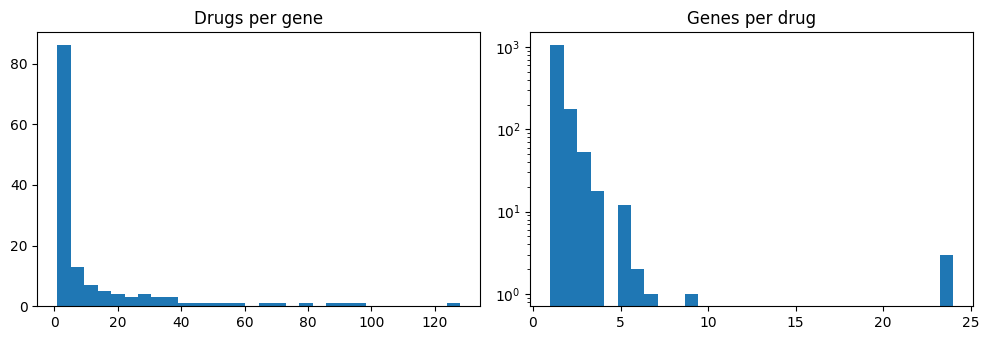

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist([G.degree(n) for n in genes_n], bins=30)
ax[0].set_title("Drugs per gene")
ax[1].hist([G.degree(d) for d in drugs_n], bins=30, log=True)
ax[1].set_title("Genes per drug")
plt.tight_layout()
plt.savefig("degree_distributions.png", dpi=200)
plt.show()

## 5. Hide test edges (leakage-free split)
Only edges whose gene **and** drug both keep another connection are eligible, so no node becomes isolated. The hidden edges are removed from `G_train`; **all features below are computed on `G_train` only.**

In [6]:
eligible = [(g, d) for g, d in pairs if G.degree(g) >= 2 and G.degree(d) >= 2]
print("total edges:", len(pairs), " eligible to hide:", len(eligible))

random.shuffle(eligible)
n_test = int(TEST_FRACTION * len(eligible))
G_train = G.copy()
test_pos = []
for g, d in eligible:
    if len(test_pos) >= n_test:
        break
    if G_train.degree(g) >= 2 and G_train.degree(d) >= 2:   # re-check after earlier removals
        G_train.remove_edge(g, d)
        test_pos.append((g, d))

print("hidden test edges:", len(test_pos))
print("training edges:", G_train.number_of_edges())

total edges: 1808  eligible to hide: 729
hidden test edges: 145
training edges: 1663


## 6. Positives, assumed negatives and features
Negatives are random gene-drug pairs with no known link anywhere in the data. They are really *unlabelled* pairs, so call them "assumed negatives" in the paper.

Features per pair: gene degree, drug degree, their product, and the number of paths of length 3 (gene - drug - gene - drug), raw and degree-normalised. Each pair's own edge is excluded so training and test pairs are scored the same way.

In [7]:
train_pos_all = [(u, v) if G_train.nodes[u]["kind"] == "gene" else (v, u) for u, v in G_train.edges()]
# FIX: test edges always had another connection on both ends, so training positives must too.
# Without this filter, most training positives (single-gene drugs) look like "degree 0" once their
# own edge is excluded, and the model learns the degree relationship backwards.
train_pos = [(g, d) for g, d in train_pos_all if G_train.degree(g) >= 2 and G_train.degree(d) >= 2]
print("training positives kept:", len(train_pos), "of", len(train_pos_all))
known = set(pairs)   # every known link in the FULL graph

def sample_negatives(n, avoid):
    out = set()
    while len(out) < n:
        g, d = random.choice(genes_n), random.choice(drugs_n)
        if (g, d) not in known and (g, d) not in avoid and (g, d) not in out:
            out.add((g, d))
    return list(out)

train_neg = sample_negatives(NEG_RATIO * len(train_pos), set())
test_neg = sample_negatives(NEG_RATIO * len(test_pos), set(train_neg))
print("train pos/neg:", len(train_pos), len(train_neg), " test pos/neg:", len(test_pos), len(test_neg))

def features(Gf, g, d):
    own = 1 if Gf.has_edge(g, d) else 0
    deg_g = Gf.degree(g) - own      # do not count the pair's own edge
    deg_d = Gf.degree(d) - own
    l3, l3n = 0, 0.0
    Ng = set(Gf[g])
    for g2 in Gf[d]:                # paths of length 3: gene - drug2 - gene2 - drug
        if g2 == g:
            continue
        for d2 in Ng & set(Gf[g2]):
            if d2 == d:
                continue
            l3 += 1
            l3n += 1 / np.sqrt(Gf.degree(d2) * Gf.degree(g2))
    return [deg_g, deg_d, deg_g * deg_d, l3, l3n]

def build(Gf, pos, neg):
    X = np.array([features(Gf, g, d) for g, d in pos + neg], dtype=float)
    return np.log1p(X), np.array([1] * len(pos) + [0] * len(neg))

X_train, y_train = build(G_train, train_pos, train_neg)
X_test, y_test = build(G_train, test_pos, test_neg)
print("feature matrices:", X_train.shape, X_test.shape)

# HARD test set: for each hidden edge keep the same gene and swap in a random drug with the SAME
# number of known genes. Degree then carries no signal, so a model must use real network structure.
from collections import defaultdict
drugs_by_deg = defaultdict(list)
for d in drugs_n:
    drugs_by_deg[G_train.degree(d)].append(d)

def matched_negatives(pos, per_pos):
    out = []
    for g, d in pos:
        pool = drugs_by_deg[G_train.degree(d)]
        got, tries = 0, 0
        while got < per_pos and tries < 300:
            d2 = random.choice(pool)
            tries += 1
            if (g, d2) not in known:
                out.append((g, d2))
                got += 1
    return out

test_neg_hard = matched_negatives(test_pos, NEG_RATIO)
X_test_hard, y_test_hard = build(G_train, test_pos, test_neg_hard)
print("hard test set:", len(test_pos), "positives,", len(test_neg_hard), "degree-matched negatives")

training positives kept: 507 of 1663
train pos/neg: 507 2535  test pos/neg: 145 725
feature matrices: (3042, 5) (870, 5)
hard test set: 145 positives, 655 degree-matched negatives


## 7. Train and evaluate
Two test sets: **random** negatives (easy) and **degree-matched** negatives (hard: same gene, drug with the same number of known genes). The degree baselines are the hub-bias check. A useful model must beat them, especially on the hard set.

In [8]:
results, scores, models = [], {}, {}

def make_lr():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight="balanced", max_iter=1000))

def score_row(name, p, y, tag):
    order = np.argsort(-p)
    return {
        "model": name, "test negatives": tag,
        "AUROC": round(roc_auc_score(y, p), 3),
        "AUPRC": round(average_precision_score(y, p), 3),
        "precision@50": round(y[order[:50]].mean(), 2),
        "precision@100": round(y[order[:100]].mean(), 2),
        "precision@200": round(y[order[:200]].mean(), 2),
    }

TESTS = [("random", X_test, y_test), ("degree-matched", X_test_hard, y_test_hard)]

def fit_and_eval(name, model, idx):
    model.fit(X_train[:, idx], y_train)
    models[name] = (model, idx)
    for tag, X, y in TESTS:
        p = model.predict_proba(X[:, idx])[:, 1]
        results.append(score_row(name, p, y, tag))
        if tag == "random":
            scores[name] = p
    return model

print("random-guess AUPRC: random negatives", round(y_test.mean(), 3),
      "| degree-matched", round(y_test_hard.mean(), 3))

# untrained popularity baseline: rank by gene degree x drug degree directly (no model, no fitting)
for tag, X, y in TESTS:
    results.append(score_row("degree product (no training)", X[:, 2], y, tag))
    if tag == "random":
        scores["degree product (no training)"] = X[:, 2]

fit_and_eval("degree product only (LR)", make_lr(), [2])
fit_and_eval("path-3 features only (LR)", make_lr(), [3, 4])
fit_and_eval("all features (LR)", make_lr(), [0, 1, 2, 3, 4])
fit_and_eval("all features (RF)",
             RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                                    random_state=SEED, n_jobs=-1),
             [0, 1, 2, 3, 4])

results_df = pd.DataFrame(results).sort_values(["test negatives", "AUROC"], ascending=[True, False])
results_df.to_csv("results_table.csv", index=False)
results_df

random-guess AUPRC: random negatives 0.167 | degree-matched 0.181


,model,test negatives,AUROC,AUPRC,precision@50,precision@100,precision@200
5,path-3 features only (LR),degree-matched,0.890,0.738,0.88,0.79,0.58
9,all features (RF),degree-matched,0.839,0.682,0.90,0.75,0.52
7,all features (LR),degree-matched,0.811,0.669,0.90,0.73,0.50
1,degree product (no training),degree-matched,0.485,0.174,0.18,0.17,0.20
3,degree product only (LR),degree-matched,0.485,0.174,0.18,0.17,0.20
6,all features (LR),random,0.953,0.881,1.00,0.93,0.63
8,all features (RF),random,0.942,0.864,1.00,0.94,0.60
4,path-3 features only (LR),random,0.929,0.870,1.00,0.97,0.64
0,degree product (no training),random,0.892,0.616,0.80,0.67,0.51
2,degree product only (LR),random,0.892,0.616,0.80,0.67,0.51


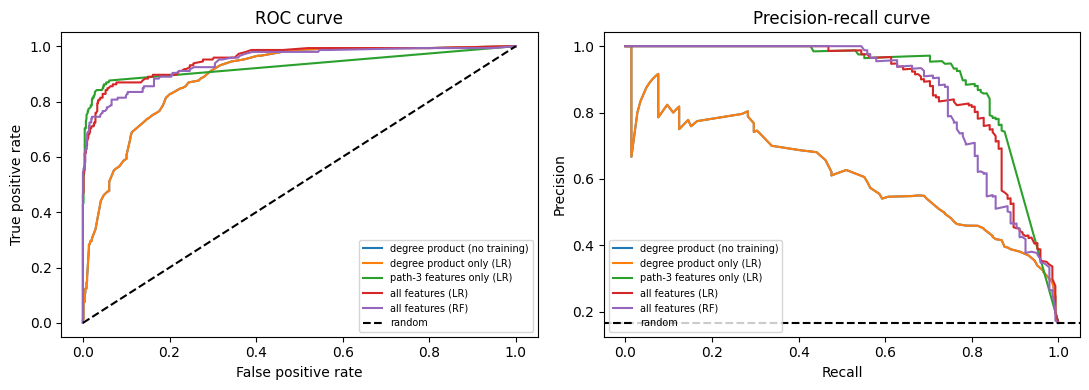

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, p in scores.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=name)
    ax[1].plot(rc, pr, label=name)
ax[0].plot([0, 1], [0, 1], "k--", label="random")
ax[0].set_title("ROC curve")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[1].axhline(y_test.mean(), color="k", ls="--", label="random")
ax[1].set_title("Precision-recall curve")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[0].legend(fontsize=7)
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig("roc_pr_curves.png", dpi=200)
plt.show()

## 8. Rank every unobserved gene-drug pair
Features are computed for all pairs at once with matrix multiplication (same definitions as above) and scored with the random forest. The score is for **ranking only**, not a probability, because of the 5:1 negative ratio. Treat the list as hypotheses and check each top pair in PubMed.

In [10]:
gi = {g: i for i, g in enumerate(genes_n)}
di = {d: i for i, d in enumerate(drugs_n)}
A = np.zeros((len(genes_n), len(drugs_n)))
for g, d in pairs:
    A[gi[g], di[d]] = 1

deg_g, deg_d = A.sum(1), A.sum(0)
wg = 1 / np.sqrt(np.maximum(deg_g, 1))
wd = 1 / np.sqrt(np.maximum(deg_d, 1))
L3 = A @ (A.T @ A)                    # paths of length 3
L3n = (A * wd) @ (A.T * wg) @ A       # degree-normalised version

DG = np.repeat(deg_g[:, None], A.shape[1], axis=1)
DD = np.repeat(deg_d[None, :], A.shape[0], axis=0)
F = np.log1p(np.stack([DG, DD, DG * DD, L3, L3n], axis=-1).reshape(-1, 5))

rf = models["all features (RF)"][0]
score = rf.predict_proba(F)[:, 1].reshape(A.shape)
score[A == 1] = -1                    # exclude pairs already known

approved = dg_t2d.drop_duplicates("drug_name").set_index("drug_name")["drug_is_approved"]
gscore = (top.assign(sym=top["symbol"].str.upper().str.strip())
             .drop_duplicates("sym").set_index("sym")["globalScore"])

best = np.dstack(np.unravel_index(np.argsort(-score, axis=None)[:30], score.shape))[0]
rows = [(genes_n[i][2:], drugs_n[j][2:], round(score[i, j], 3),
         approved.get(drugs_n[j][2:]), round(gscore.get(genes_n[i][2:], np.nan), 3))
        for i, j in best]
top_pred = pd.DataFrame(rows, columns=["gene", "drug", "model_score", "approved", "T2D_score"])
top_pred.to_csv("top_predictions.csv", index=False)
top_pred

,gene,drug,model_score,approved,T2D_score
0,FGFR3,RECOMBINANT FIBROBLAST GROWTH FACTOR 6,1.0,False,0.449
1,FGFR3,ROBLITINIB,1.0,False,0.449
2,FGFR3,FGFR4 ANTAGONIST INCB062079,1.0,False,0.449
3,FGFR3,IONIS-FGFR4RX,1.0,False,0.449
4,FGFR3,XL-999,1.0,False,0.449
5,FGFR3,ORANTINIB,1.0,False,0.449
6,FGFR3,FGFR4 INHIBITOR BLU 9931,1.0,False,0.449
7,FGFR3,H3B-6527,1.0,False,0.449
8,FGFR3,BRIVANIB ALANINATE,1.0,False,0.449
9,FGFR3,FISOGATINIB,1.0,False,0.449


In [16]:
cand = []
for i, g in enumerate(genes_n):
    for j in np.argsort(-score[i])[:3]:
        if score[i, j] > 0:
            cand.append((g[2:], drugs_n[j][2:], round(score[i, j], 3)))
div = pd.DataFrame(cand, columns=["gene", "drug", "model_score"])
div["T2D_score"] = div["gene"].map(gscore).round(3)
div = div.sort_values(["model_score", "T2D_score"], ascending=False)
div.head(30)

,gene,drug,model_score,T2D_score
189,PPARG,GLIMEPIRIDE,1.000,0.861
190,PPARG,ACETOHEXAMIDE,1.000,0.861
191,PPARG,GLYBURIDE,1.000,0.861
171,AKT2,SIROLIMUS,1.000,0.721
153,FGFR4,TOZASERTIB,1.000,0.575
154,FGFR4,DOCETAXEL ANHYDROUS,1.000,0.575
155,FGFR4,MLN-8054,1.000,0.575
321,PDE4B,LEVOSIMENDAN,1.000,0.492
12,FGFR3,RECOMBINANT FIBROBLAST GROWTH FACTOR 6,1.000,0.449
13,FGFR3,H3B-6527,1.000,0.449


In [21]:
for dname in top_pred.head(10)["drug"]:
    print(dname, "->", sorted(dg_t2d.loc[dg_t2d["drug_name"] == dname, "gene_name"]))


RECOMBINANT FIBROBLAST GROWTH FACTOR 6 -> ['FGFR4']
ROBLITINIB -> ['FGFR4']
FGFR4 ANTAGONIST INCB062079 -> ['FGFR4']
IONIS-FGFR4RX -> ['FGFR4']
XL-999 -> ['FGFR4']
ORANTINIB -> ['FGFR4']
FGFR4 INHIBITOR BLU 9931 -> ['FGFR4']
H3B-6527 -> ['FGFR4']
BRIVANIB ALANINATE -> ['FGFR4']
FISOGATINIB -> ['FGFR4']


In [ ]:
print([c for c in dg.columns if "interaction" in c or "type" in c])

['interaction_source_db_name', 'interaction_source_db_version', 'interaction_types', 'interaction_score']


In [15]:
import urllib.parse
for r in top_pred.head(10).itertuples():
    q = urllib.parse.quote_plus(f"{r.gene} AND {r.drug}")
    print(f"{r.gene} - {r.drug}: https://pubmed.ncbi.nlm.nih.gov/?term={q}")

FGFR3 - RECOMBINANT FIBROBLAST GROWTH FACTOR 6: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+RECOMBINANT+FIBROBLAST+GROWTH+FACTOR+6
FGFR3 - ROBLITINIB: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+ROBLITINIB
FGFR3 - FGFR4 ANTAGONIST INCB062079: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+FGFR4+ANTAGONIST+INCB062079
FGFR3 - IONIS-FGFR4RX: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+IONIS-FGFR4RX
FGFR3 - XL-999: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+XL-999
FGFR3 - ORANTINIB: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+ORANTINIB
FGFR3 - FGFR4 INHIBITOR BLU 9931: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+FGFR4+INHIBITOR+BLU+9931
FGFR3 - H3B-6527: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+H3B-6527
FGFR3 - BRIVANIB ALANINATE: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+BRIVANIB+ALANINATE
FGFR3 - FISOGATINIB: https://pubmed.ncbi.nlm.nih.gov/?term=FGFR3+AND+FISOGATINIB


In [11]:
# --- sanity checks on the ranking ---
flat = np.sort(score.ravel())[::-1]
print("top score:", round(flat[0], 3), "| pairs tied at the top score:", int((score == flat[0]).sum()))
print("pairs scoring >= 0.95:", int((score >= 0.95).sum()))

deg_rank = (DG * DD).reshape(A.shape).astype(float)
deg_rank[A == 1] = -1
def top_set(m, k=200):
    return {tuple(x) for x in np.dstack(np.unravel_index(np.argsort(-m, axis=None)[:k], m.shape))[0]}
tm, td = top_set(score), top_set(deg_rank)
print("overlap of model top 200 with degree-only top 200:", len(tm & td))
print("distinct genes in model top 200:", len({i for i, j in tm}), "| distinct drugs:", len({j for i, j in tm}))

top score: 1.0 | pairs tied at the top score: 25
pairs scoring >= 0.95: 1115
overlap of model top 200 with degree-only top 200: 6
distinct genes in model top 200: 14 | distinct drugs: 137


## 9. Save outputs
Download these from the Files panel (Colab deletes files when the session resets): `degree_distributions.png`, `roc_pr_curves.png`, `results_table.csv`, `top_predictions.csv`, `decisions_log.md`.

## Limitations to state in the paper
- DGIdb rows without a standard drug name were dropped, so some real links are missing.
- Negatives are assumed (unlabelled), not confirmed.
- Hub genes and drugs dominate simple scores; compare against the degree-only baseline.
- Test edges only include genes and drugs that keep another connection, so brand-new (cold-start) drugs are not evaluated.
- Predictions are hypotheses and need literature and experimental validation.

In [12]:
from collections import defaultdict

SEEDS = [1, 2, 3, 4, 5]

def split_graph(seed):
    random.seed(seed)
    elig = [(g, d) for g, d in pairs if G.degree(g) >= 2 and G.degree(d) >= 2]
    random.shuffle(elig)
    n_t = int(TEST_FRACTION * len(elig))
    Gt, tpos = G.copy(), []
    for g, d in elig:
        if len(tpos) >= n_t:
            break
        if Gt.degree(g) >= 2 and Gt.degree(d) >= 2:
            Gt.remove_edge(g, d)
            tpos.append((g, d))
    return Gt, tpos

def matched_neg(Gt, pos, per_pos):
    by_deg = defaultdict(list)
    for d in drugs_n:
        by_deg[Gt.degree(d)].append(d)
    out = []
    for g, d in pos:
        pool, got, tries = by_deg[Gt.degree(d)], 0, 0
        while got < per_pos and tries < 300:
            d2 = random.choice(pool)
            tries += 1
            if (g, d2) not in known:
                out.append((g, d2))
                got += 1
    return out

In [14]:

def one_run(seed):
    Gt, tpos = split_graph(seed)
    tr_all = [(u, v) if Gt.nodes[u]["kind"] == "gene" else (v, u) for u, v in Gt.edges()]
    trpos = [(g, d) for g, d in tr_all if Gt.degree(g) >= 2 and Gt.degree(d) >= 2]
    n_neg = NEG_RATIO * len(trpos)

    tr_neg = {"random": sample_negatives(n_neg, set()),
              "degree-matched": matched_neg(Gt, trpos, NEG_RATIO)}
    te_neg = {"random": sample_negatives(NEG_RATIO * len(tpos), set(tr_neg["random"])),
              "degree-matched": matched_neg(Gt, tpos, NEG_RATIO)}
    tests = {k: build(Gt, tpos, v) for k, v in te_neg.items()}

    rows = []
    for tag, (X, y) in tests.items():
        r = score_row("degree product (no training)", X[:, 2], y, tag)
        r.update(seed=seed, trained_on="n/a")
        rows.append(r)

    for train_tag, negs in tr_neg.items():
        Xtr, ytr = build(Gt, trpos, negs)
        specs = [("path-3 features only (LR)", make_lr(), [3, 4]),
                 ("all features (LR)", make_lr(), [0, 1, 2, 3, 4]),
                 ("all features (RF)",
                  RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                         class_weight="balanced", random_state=seed, n_jobs=-1),
                  [0, 1, 2, 3, 4])]
        for name, model, idx in specs:
            model.fit(Xtr[:, idx], ytr)
            for tag, (X, y) in tests.items():
                p = model.predict_proba(X[:, idx])[:, 1]
                r = score_row(name, p, y, tag)
                r.update(seed=seed, trained_on=train_tag)
                rows.append(r)
    return rows

all_rows = []
for s in SEEDS:
    all_rows += one_run(s)
    print("finished seed", s)

ms = pd.DataFrame(all_rows)
ms.to_csv("multi_seed_raw.csv", index=False)
summary = (ms.groupby(["test negatives", "trained_on", "model"])[["AUROC", "AUPRC"]]
             .agg(["mean", "std"]).round(3))
summary.to_csv("multi_seed_results.csv")
summary

finished seed 1
finished seed 2
finished seed 3
finished seed 4
finished seed 5


AUROC         \
                                                             mean    std   
test negatives trained_on     model                                        
degree-matched degree-matched all features (LR)             0.775  0.012   
                              all features (RF)             0.558  0.043   
                              path-3 features only (LR)     0.830  0.016   
               n/a            degree product (no training)  0.495  0.003   
               random         all features (LR)             0.784  0.019   
                              all features (RF)             0.805  0.020   
                              path-3 features only (LR)     0.829  0.016   
random         degree-matched all features (LR)             0.587  0.034   
                              all features (RF)             0.347  0.041   
                              path-3 features only (LR)     0.875  0.015   
               n/a            degree product (no training)  0.878  0.007   
               random         all features (LR)             0.942  0.008   
                              all features (RF)             0.922  0.011   
                              path-3 features only (LR)     0.875  0.015   

                                                            AUPRC         
                                                             mean    std  
test negatives trained_on     model                                       
degree-matched degree-matched all features (LR)             0.588  0.028  
                              all features (RF)             0.222  0.020  
                              path-3 features only (LR)     0.650  0.031  
               n/a            degree product (no training)  0.182  0.008  
               random         all features (LR)             0.620  0.032  
                              all features (RF)             0.631  0.040  
                              path-3 features only (LR)     0.644  0.033  
random         degree-matched all features (LR)             0.529  0.024  
                              all features (RF)             0.171  0.031  
                              path-3 features only (LR)     0.772  0.020  
               n/a            degree product (no training)  0.555  0.038  
               random         all features (LR)             0.841  0.013  
                              all features (RF)             0.823  0.019  
                              path-3 features only (LR)     0.770  0.020